In [1]:
import numpy as np
import matplotlib.pyplot as plt
from copy import deepcopy
from profit_optimisation_model.src.HydraulicConductanceModels.cumulative_Weibull_distribution_model import cumulative_Weibull_distribution
from profit_optimisation_model.src.HydraulicConductanceModels.cumulative_Weibull_distribution_model import cumulative_Weibull_distribution_from_conductance_loss_at_given_water_potentials

# Impact of LAI on Kmax
Stomatal optimisation models account for the impact of LAI on GPP and LE by simply multiplying by LAI. This however assumes that the conductive tissue for each leaf is entirely independent. In reality, the conductive tissue within a branch is shared between the subset of leaves connected through that branch to the soil. While adding (removing) a leaf from the end of a branch increases (decreases) the hydraulic demand through the branch it doesn't change the maximum conductance of the branch, leading to a grater (smaller) difference in water potential across the branch.

## Modelling branching
Before we can run any calculations we need to create a model of how the tree branches. Our tree will consist of two classes, branches and leaves. 

Each branch is assumed to split into two subbranches. The maximum number of leaves a branch can support (and its capacitance) is split between its subbranches. Where a subbranch can only support one leaf we instead add a leaf finishing that part of the tree.

In [2]:
class BranchPoint:
    _max_leaf_support = None
    _branches = None
    _vulnerability_curve = None
    _length = None
    _water_potential = None
    _transpiration = None
    _branch_order = None
    
    def __init__(self, max_leaf_support, vulnerability_curve, length, splitting_function, leaf_points_list, leaf_transpiration, leaf_exists, branch_order):
        """
        
        @param max_leaf_support: Number of leaves this branch can support.
        @param vulnerability_curve: HydraulicConductanceModel
        @param lengh: Branch length (m).
        @param splitting_function: Function to calculate how leaf support is split between subbranches.
        @param leaf_points_list: List of leaves to add to.
        @param leaf_transpiration: Transpiration rate of leaf.
        @param leaf_exists: Set if leaves exist.
        @param branch_order: Number of branching points from trunk.
        """
        
        self._max_leaf_support = max_leaf_support
        self._vulnerability_curve = vulnerability_curve
        self._length = length
        self._branch_order = branch_order
        
        # Calculate how the leaves are split among the branches.
        branch_leaf_support = splitting_function(max_leaf_support)
        
        # Create the different branches attached to this branch.
        self._branches = []
        for i in range(len(branch_leaf_support)):
            # If there is only space for one leaf left add a leaf
            if 1 == branch_leaf_support[i]:
                self._branches.append( Leaf(leaf_transpiration, leaf_exists, branch_order+1))
                
                # Add to the list of leaf points for ease of changing transpiration
                leaf_points_list.append(self._branches[-1])
                
            else:
                # Make a new vulnerability curve for the branch
                new_vulnerability_curve = deepcopy(vulnerability_curve)
                # Set the conductance values for the new branch
                new_vulnerability_curve._base_k_max *= float(branch_leaf_support[i])/float(max_leaf_support)
                new_vulnerability_curve._k_max *= float(branch_leaf_support[i])/float(max_leaf_support)
                
                # Make the new branch and add it to the list.
                self._branches.append(BranchPoint(branch_leaf_support[i],
                                                  new_vulnerability_curve,
                                                  length,
                                                  splitting_function,
                                                  leaf_points_list,
                                                  leaf_transpiration, 
                                                  leaf_exists,
                                                  branch_order+1))
        
        
    
    def get_max_leaf_support(self):
        return self._max_leaf_support
    
    def get_branches(self):
        return self._branches
    
    def get_kmax(self):
        return self._vulnerability_curve.maximum_conductance
    
    def get_length(self):
        return self._length
    
    def get_water_potential(self):
        return self._water_potential
    
    def get_transpiration(self):
        self._transpiration = 0
        
        # Sum over the transpiration rates from all the subbranches
        for i in range(len(self._branches)):
            self._transpiration += self._branches.get_transpiration()
        
        return self._transpiration
    
    def set_water_potential(self, parent_water_potential, step_size = 0.1, max_steps = 1000):
        
        # If this is the root node recalculate transpiration and water potentials for all nodes
        if(self._branch_order == 0):
            
            # Calculate all transpiration rates through branches.
            self.get_transpiration()
            
        # Calculate the water potential at the branch point.
        self._water_potential = self._vulnerability_curve.water_potnetial_from_transpiration(self._transpiration,
                                                                                             parent_water_potential,
                                                                                             setp_size = step_size, 
                                                                                             max_steps = max_steps)
        
        for i in range(len(self._branches)):
            self._branches[i].set_water_potential(self._water_potential,
                                                  step_size = step_size,
                                                  max_steps = max_steps)
            
        return self._water_potential
            
        
        
    

All the branches end in points where a leaf can exist. If the leaf does exist then it draws water through the tree based on its transpiration rate.

In [3]:
class Leaf:
    _transpiration = None
    _exists = False
    _leaf_water_potential = None
    _branch_order = None
    
    def __init__(self, transpiration, exists, branch_order):
        self._transpiration = transpiration
        self._exists = exists
        self._branch_order = branch_order
    
    def get_transpiration(self):
        # If the leaf exists return the transpiration rate
        if self._exists:
            return self._transpiration
        
        # If the leaf doesn't exist return zero
        return 0.
    
    def set_transpiration(self, transpiration):
        self._transpiration = transpiration
    
    def add_leaf(self):
        self._exists = True
        
    def remove_leaf(self):
        self._exists = False
        
    def leaf_exists(self):
        return self._exists
        
    def set_leaf_water_potential(self, leaf_water_potential):
        self._leaf_water_potential = leaf_water_potential

We need to create a function to determine how a branch splits its leaf support among its subbranches. To do this we use a beta distribution to calculate the fraction then convert to an integer number to set the leaf support of both subbranches.

In [4]:
def branch_split(max_leaf_support, a, b):
    """
    
    @param leaf_support: Number of leaves to split between the two branches
    @param a: beat distribution a parameter
    @param b: beat distribution b parameter
    @return: max leaf support of the two branches
    """
    split_fraction = np.random.beta(a,b)
    left_leaf_support = 1 + int((float(max_leaf_support)-1.) * split_fraction)
    
    return np.asarray([left_leaf_support, max_leaf_support-left_leaf_support], int)


First we check the distribution of leaf supports from the branch_split function.

20


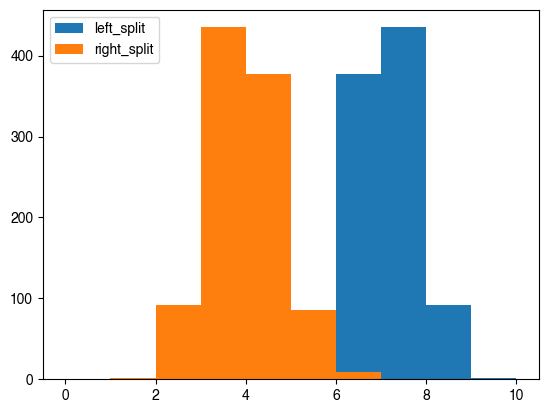

In [5]:
run_count = 1000
max_leaf_support = 10
beta_a = 10
beta_b = 20

if(beta_a < beta_b):
    tmp = beta_b
    beta_b = beta_a
    beta_a = tmp

support_values = np.zeros([run_count,2])

for i in range(run_count):
    support_values[i] = branch_split(max_leaf_support, beta_a, beta_b)

plt.hist(support_values[:,0], bins=np.linspace(0,max_leaf_support, max_leaf_support+1), label="left_split")
plt.hist(support_values[:,1], bins=np.linspace(0,max_leaf_support, max_leaf_support+1), label="right_split")
plt.legend()
plt.show()

Now we test the tree construction with a small tree.

100


(<Figure size 640x480 with 1 Axes>, <Axes: >)

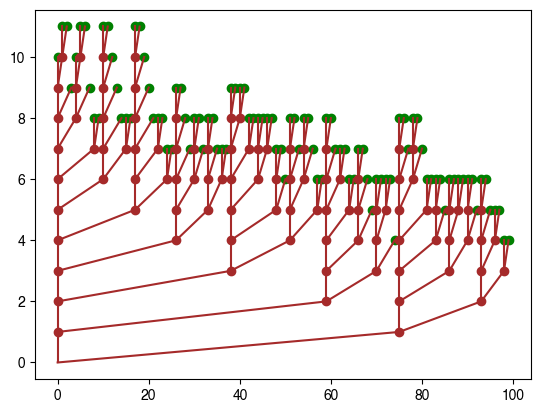

In [6]:
P50 = -2.83
P88 = -3.41

cumulative_Weibull_vulnerability_curve = cumulative_Weibull_distribution_from_conductance_loss_at_given_water_potentials(1., P50, P88, 0.5, 0.88)

leaf_points = []

def splitting_function(max_leaf_support):
    return branch_split(max_leaf_support, beta_a, beta_b)

max_leaf_support = 100

trunk = BranchPoint(max_leaf_support, cumulative_Weibull_vulnerability_curve, 1, splitting_function, leaf_points, 1, True, branch_order = 0)

print(len(leaf_points))

def plot_branch(branch, fig, axs, x_position, y_position, branch_colour = "brown", leaf_colour = "green"):
    
    if(type(branch) == Leaf):
        if(branch.leaf_exists()):
            axs.scatter(x_position, y_position, c=leaf_colour)
        else:
            axs.scatter(x_position, y_position, c="grey")
        return x_position + 1
    
    axs.scatter(x_position,y_position, c=branch_colour)
    
    branch_x_position = x_position
    
    for current_branch in branch.get_branches():
        axs.plot([x_position, branch_x_position], [y_position, y_position+branch.get_length()], c=branch_colour)
        
        branch_x_position = plot_branch(current_branch, fig, axs, branch_x_position, y_position + trunk.get_length())
    
    return branch_x_position

def plot_tree(trunk, branch_colour = "brown", leaf_colour = "green"):
    fig, axs = plt.subplots(1,1)
    
    x_position = 0
    y_position = 0
    
    branch_x_position = x_position
    
    for current_branch in trunk.get_branches():
        
        axs.plot([x_position, branch_x_position], [y_position, y_position+trunk.get_length()], c=branch_colour)
        
        branch_x_position = plot_branch(current_branch,
                                        fig,
                                        axs,
                                        branch_x_position,
                                        y_position + trunk.get_length(),
                                        branch_colour,
                                        leaf_colour
                                        )
    
    return fig, axs
    
plot_tree(trunk)